In [21]:
import os
import sys
from glob import glob
import time

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# to import logger, VR-wide constants and device paths  
sys.path.append(os.path.join('.', ".."))
sys.path.append(os.path.join('..', ".."))
# sys.path.append(os.path.join(".", "publication_figures")); sys.path.append(".")   # run from the repo root or from publication_figures
from baseVR.base_logger import CustomLogger as Logger
from baseVR.base_functionality import device_paths



from fig_style import setup_style
from export_figure import export_figure

from dac_calibration_plots import make_figure, plot_transfer, style_axes, excluded_sweeps  # circuit, panels and figure assembly live in the lib

nas_dir = device_paths()[0]
setup_style()


In [22]:
L = Logger()
L.init_logger(None, None, "WARNING")

Logging at level WARNING


In [23]:
subdir = f"devices/well_devices/4983/recordings"
subdir = f"devices/well_devices/3774/recordings"
subdir = f"devices/well_devices/4988/recordings"


outdir = os.path.join(nas_dir, 'mea1k_paper', "dac_calibration")

In [ ]:

# 1M
rec_dir = "2026-10-25_22.37_R=1024000_CharStim_ShowCase2_small_current"

# 100k
rec_dir = "2026-10-26_17.32_R=100000_CharStim_ShowCase2_large_current"
rec_dir = "2026-10-26_21.53_R=100000_CharStim_ShowCase2_small_current"

rec_dir = "2026-10-27_12.07_R=100000_CharStim_ShowCase2_gain112_small_current"
rec_dir = "2026-10-27_14.16_R=100000_CharStim_ShowCase2_gain1_small_current"
rec_dir = "2026-10-27_16.58_R=100000_CharStim_ShowCase2_gain1_large_current"

# 1 MOhm
# only did partial run, was very nice and low noise, but again off by 15% roughly, for both SC abd LC
# rec_dir = "2026-10-28_14.24_R=1000000_CharStim_ShowCase2_gain1_large_current"
rec_dir = "2026-10-28_14.36_R=1000000_CharStim_ShowCase2_gain1_small_current"

# trying with other well chips  BOTH AGREE: ON 1moHM ITS 13-15% TOO LOW VOLTAGE, chip independent
rec_dir = "2026-10-28_17.31_R=1000000_CharStim_ShowCase2_gain1_large_current"
rec_dir = "2026-10-28_17.37_R=1000000_CharStim_ShowCase2_gain1_large_current"

# load resistor in the calibration circuit [Ohm]; read from the recording name, override here if needed
import re
R_LOAD_OHM = float(re.search(r"R=(\d+)", rec_dir).group(1))
# recording gain, from "gainN" in the recording name; None = the global MEA_OVERRIDE_GAIN (ephys_constants.py)
GAIN = float(re.search(r"gain(\d+)", rec_dir).group(1)) if "gain" in rec_dir else None

results = []
for fname in glob(os.path.join(nas_dir, subdir, rec_dir, "results_*.csv")):
    # L.info(f"Reading {fname}")
    df = pd.read_csv(fname)
    results.append(df)
results = pd.concat(results, axis=0, ignore_index=True)
results

,stimunit_id,ampl_id,set_id,DAC_val,peak_uV,peak_at,baseline,sensed_current_uA_at_peak
0,5.0,268.0,1.0,489.0,937793.0,1345.0,22559.0,-1.116031
1,5.0,268.0,1.0,491.0,831445.0,1239.0,22559.0,-0.993158
2,5.0,268.0,1.0,493.0,705761.0,984.0,22559.0,-0.864321
3,5.0,268.0,1.0,495.0,583300.0,1017.0,22559.0,-0.715848
4,5.0,268.0,1.0,497.0,457617.0,1214.0,22559.0,-0.576263
...,...,...,...,...,...,...,...,...
439,5.0,268.0,0.0,520.0,-960352.0,1009.0,22559.0,1.054830
440,5.0,268.0,0.0,524.0,-1144043.0,1213.0,22559.0,1.265981
441,5.0,268.0,0.0,532.0,-1269727.0,1225.0,22559.0,1.407721
442,5.0,268.0,0.0,536.0,-1285840.0,1492.0,22559.0,1.425105


## Figure: stim-unit DAC calibration
a) circuit (load R from the recording name, `R_LOAD_OHM`), one branch per trace row of b; b) recording scheme of one sweep file: DAC command, recorded amplifier voltage and PicoScope current, aligned in time (dots = the values that enter c-e); c) DAC code → current through R (linear part of the sigmoid); d) DAC code → recorded amplifier voltage; e) voltage vs current, with the linear-regime fit that gives R; f) current LSB per stim unit: |dV/dDAC| / R from the amplifier voltage (what is available in vivo) against the slope of the PicoScope current in c. d and e share the voltage axis, c and d the DAC axis. Dashed lines: zero-current DAC code of each stim unit. One colour per stim unit, ordered by zero-crossing DAC code (`color_by="id"` orders by unit id instead).
Works for `large_current` and `small_current` recordings: set `rec_dir` in the cell that loads `results` (panel b reads the raw `.raw.h5` / `.npz` files of that recording). `make_figure` also returns a caption describing the post-processing.

In [25]:
fig, fits, colors, caption = make_figure(results, os.path.join(nas_dir, subdir, rec_dir), 
                                         R_ohm=R_LOAD_OHM, gain=GAIN)
# A4 page, png or svg; set the path to wherever the figure should go
# export_figure(fig, os.path.join(outdir, "fig_DAC_calibr_100kSC"), 
#               fmt="svg", canvas="a4")
print(caption)
print(fits.describe().loc[["mean", "std", "min", "max"], ["slope_uA_per_lsb", "dac0"]])
print("sweeps excluded from c, e, f (no stimulus pulse recorded):")
print(excluded_sweeps(results, fits).to_string())

Calibration of the 10 stimulation units into a 1 M$\Omega$ load (20 readout amplifiers, 2 sweeps). (b) Raw traces of five sweep files of stim. unit 5: DAC command, MEA1K amplifier voltage and PicoScope current (sense resistor 10 k$\Omega$, x100 amplifier). Amplifier voltage: baseline (median of the first 500 samples) subtracted, otherwise unfiltered. Current: unfiltered, no offset correction. MaxWell and PicoScope are not synchronised: each current trace is shifted onto the voltage trace by the delay between their connect edges (8.1-9.9 ms here; edge = half maximum of the 15-sample-smoothed |trace|; files without a visible edge use the median shift). t = 0 is the connect edge in the voltage trace. Dots: values entering (c-e). Voltage = peak of the baseline-subtracted amplifier trace after a 2 kHz low-pass, taken on the plateau after the connect transient; current = PicoScope sample at the same sample index, without the shift above. (c) Current per DAC code, mean over amplifiers and swe

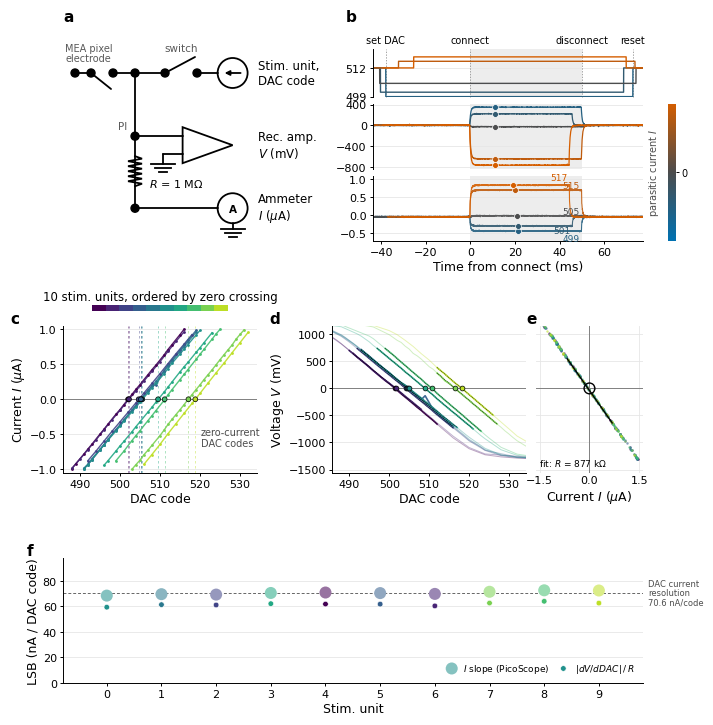

In [26]:
plt.show()